<a href="https://colab.research.google.com/github/bu11ymaguire/SKT_FLY_AI_8/blob/main/12_24_vol2_diabetes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 이진분류 - 피마인디언 당뇨병 데이터

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
import random
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
np.set_printoptions(precision=4,linewidth=200)

In [3]:
!wget 'https://raw.githubusercontent.com/devdio/flyai_datasets/refs/heads/main/diabetes.csv'

--2025-12-24 02:24:34--  https://raw.githubusercontent.com/devdio/flyai_datasets/refs/heads/main/diabetes.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 23873 (23K) [text/plain]
Saving to: ‘diabetes.csv’

diabetes.csv        100%[===================>]  23.31K  --.-KB/s    in 0.002s  

2025-12-24 02:24:34 (10.7 MB/s) - ‘diabetes.csv’ saved [23873/23873]



In [7]:
df = pd.read_csv("/content/diabetes.csv")
df.shape

(768, 9)

In [8]:
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


##EDA

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [11]:
df.describe().T
#min이 조금 이상한게 있다 -> 도메인 지식 필요

,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.845052,3.369578,0.000,1.00000,3.0000,6.00000,17.00
Glucose,768.0,120.894531,31.972618,0.000,99.00000,117.0000,140.25000,199.00
BloodPressure,768.0,69.105469,19.355807,0.000,62.00000,72.0000,80.00000,122.00
SkinThickness,768.0,20.536458,15.952218,0.000,0.00000,23.0000,32.00000,99.00
Insulin,768.0,79.799479,115.244002,0.000,0.00000,30.5000,127.25000,846.00
BMI,768.0,31.992578,7.884160,0.000,27.30000,32.0000,36.60000,67.10
DiabetesPedigreeFunction,768.0,0.471876,0.331329,0.078,0.24375,0.3725,0.62625,2.42
Age,768.0,33.240885,11.760232,21.000,24.00000,29.0000,41.00000,81.00
Outcome,768.0,0.348958,0.476951,0.000,0.00000,0.0000,1.00000,1.00


##타깃값

In [13]:
df['Outcome'].value_counts()

,count
Outcome,
0,500
1,268


In [14]:
df["Pregnancies"].value_counts().T

,count
Pregnancies,
1,135
0,111
2,103
3,75
4,68
5,57
6,50
7,45
8,38


In [15]:
df.isna().sum()

,0
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Outcome,0


In [17]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.845052,3.369578,0.000,1.00000,3.0000,6.00000,17.00
Glucose,768.0,120.894531,31.972618,0.000,99.00000,117.0000,140.25000,199.00
BloodPressure,768.0,69.105469,19.355807,0.000,62.00000,72.0000,80.00000,122.00
SkinThickness,768.0,20.536458,15.952218,0.000,0.00000,23.0000,32.00000,99.00
Insulin,768.0,79.799479,115.244002,0.000,0.00000,30.5000,127.25000,846.00
BMI,768.0,31.992578,7.884160,0.000,27.30000,32.0000,36.60000,67.10
DiabetesPedigreeFunction,768.0,0.471876,0.331329,0.078,0.24375,0.3725,0.62625,2.42
Age,768.0,33.240885,11.760232,21.000,24.00000,29.0000,41.00000,81.00
Outcome,768.0,0.348958,0.476951,0.000,0.00000,0.0000,1.00000,1.00


In [18]:
zero_clos = ["Glucose","BloodPressure","SkinThickness","Insulin","BMI"]

In [19]:
for i, col in enumerate(zero_clos):
  print(f"{col}:{len(df[df[col]==0])}")

Glucose:5
BloodPressure:35
SkinThickness:227
Insulin:374
BMI:11


##데이터 분리

In [21]:
from sklearn.model_selection import train_test_split

train, test = train_test_split(
    df,
    test_size=0.2,
    shuffle = True,
    stratify=df["Outcome"],
    random_state = SEED
)

In [22]:
train["Outcome"].value_counts()

,count
Outcome,
0,400
1,214


In [23]:
test["Outcome"].value_counts()

,count
Outcome,
0,100
1,54


In [24]:
x_train = train.drop('Outcome',axis = 1)
y_train = train['Outcome']

In [25]:
x_train.shape, y_train.shape

((614, 8), (614,))

## 데이터 전처리

In [29]:
x_train[zero_clos] = x_train[zero_clos].replace(0,np.nan)

In [30]:
x_train[zero_clos]

,Glucose,BloodPressure,SkinThickness,Insulin,BMI
353,90.0,62.0,12.0,43.0,27.2
711,126.0,78.0,27.0,22.0,29.6
373,105.0,58.0,40.0,94.0,34.9
46,146.0,56.0,NaN,NaN,29.7
682,95.0,64.0,39.0,105.0,44.6
...,...,...,...,...,...
451,134.0,70.0,NaN,NaN,28.9
113,76.0,62.0,NaN,NaN,34.0
556,97.0,70.0,40.0,NaN,38.1
667,111.0,70.0,27.0,NaN,27.5


In [31]:
mean_dic = {}

for col in zero_clos:
  u = x_train[col].mean()
  x_train[col] = x_train[col].fillna(u)
  mean_dic[col] = u

In [32]:
mean_dic

{'Glucose': np.float64(121.70163934426229),
 'BloodPressure': np.float64(72.14551607445009),
 'SkinThickness': np.float64(29.059225512528474),
 'Insulin': np.float64(149.07716049382717),
 'BMI': np.float64(32.44892561983471)}

In [33]:
x_train.isna().sum()

,0
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0


In [34]:
x_train.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
353,1,90.0,62.0,12.000000,43.00000,27.2,0.580,24
711,5,126.0,78.0,27.000000,22.00000,29.6,0.439,40
373,2,105.0,58.0,40.000000,94.00000,34.9,0.225,25
46,1,146.0,56.0,29.059226,149.07716,29.7,0.564,29
682,0,95.0,64.0,39.000000,105.00000,44.6,0.366,22


##스케일링

In [35]:
from sklearn.preprocessing import StandardScaler

ss = StandardScaler()
ss.fit(x_train)

x_train_s = ss.transform(x_train)
x_train_s

array([[-0.8514, -1.0575, -0.8272, ..., -0.7698,  0.3108, -0.7922],
       [ 0.3566,  0.1434,  0.4773, ..., -0.4178, -0.1164,  0.561 ],
       [-0.5494, -0.5571, -1.1533, ...,  0.3595, -0.7649, -0.7076],
       ...,
       [-0.8514, -0.824 , -0.1749, ...,  0.8288, -0.7861, -0.2847],
       [ 1.8665, -0.357 , -0.1749, ..., -0.7258, -1.0194,  0.561 ],
       [ 0.0546,  0.7438, -1.1533, ..., -0.4325, -0.577 ,  0.3073]])

In [37]:
y_train = y_train.to_numpy()

## 최종 테스트 데이터

In [38]:
type(x_train_s), type(y_train), x_train.shape, y_train.shape

(numpy.ndarray, numpy.ndarray, (614, 8), (614,))

## 베이스라인 모델

In [39]:
from sklearn.svm import SVC

svc = SVC(random_state=SEED)
svc.fit(x_train_s,y_train)

SVC(random_state=42)

In [44]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "kernel":["linear","poly","rbf","sigmoid"],
    "C":[0.1,0.5,1,3,5,7] ,"gamma":["scale","auto"]
}

In [45]:
grid_search = GridSearchCV(
    SVC(random_state=SEED),
    param_grid,
    cv=5,
    scoring="accuracy",
    refit=True,
    verbose =1,
    n_jobs = -1
    )

In [46]:
grd_search = grid_search.fit(x_train_s,y_train)

Fitting 5 folds for each of 48 candidates, totalling 240 fits


In [47]:
grd_search

GridSearchCV(cv=5, estimator=SVC(random_state=42), n_jobs=-1,
             param_grid={'C': [0.1, 0.5, 1, 3, 5, 7],
                         'gamma': ['scale', 'auto'],
                         'kernel': ['linear', 'poly', 'rbf', 'sigmoid']},
             scoring='accuracy', verbose=1)

In [48]:
grid_search.best_params_

{'C': 0.5, 'gamma': 'scale', 'kernel': 'linear'}

In [50]:
grid_search.best_score_

np.float64(0.775303212048514)

## 테스트

In [52]:
from sklearn.metrics import accuracy_score,precision_score
from sklearn.metrics import recall_score,f1_score
from sklearn.metrics import confusion_matrix

def print_metrics(y_true, y_pred):
    acc = accuracy_score(y_true, y_pred)
    pre = precision_score(y_true, y_pred)
    recall = recall_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)

    print(f"정확도 {acc}")
    print(f"정밀도 {pre}")
    print(f"재현율 {recall}")
    print(f"f1 {f1}")

    cfm = confusion_matrix(y_true,y_pred)

    s = sns.heatmap( cfm,annot=True, fmt='d',cbar=False )
    s.set( xlabel='Prediction',ylabel='Actual')
    plt.show()

In [57]:
x_test = test.drop('Outcome',axis = 1)
y_test = test['Outcome']

In [58]:
x_test[zero_clos] = x_test[zero_clos].replace(0,np.nan)
x_test[zero_clos]

,Glucose,BloodPressure,SkinThickness,Insulin,BMI
44,159.0,64.0,NaN,NaN,27.4
672,68.0,106.0,23.0,49.0,35.5
700,122.0,76.0,27.0,200.0,35.9
630,114.0,64.0,NaN,NaN,27.4
81,74.0,NaN,NaN,NaN,NaN
...,...,...,...,...,...
32,88.0,58.0,11.0,54.0,24.8
637,94.0,76.0,18.0,66.0,31.6
593,82.0,52.0,22.0,115.0,28.5
425,184.0,78.0,39.0,277.0,37.0


In [59]:
for col in zero_clos:
  u = mean_dic[col]
  x_test[col] = x_test[col].fillna(u)

In [60]:
x_test.isna().sum()

,0
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0


In [61]:
x_test_s = ss.transform(x_test)
y_test = y_test.to_numpy()

# 다른 모델 학습

In [68]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression

model = {
    "knn":KNeighborsClassifier(),
    "dt":DecisionTreeClassifier(random_state=SEED),
    "rf":RandomForestClassifier(),
}



정확도 0.7402597402597403
정밀도 0.6296296296296297
재현율 0.6296296296296297
f1 0.6296296296296297


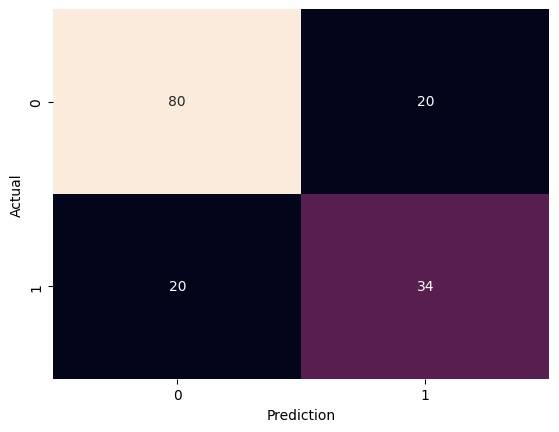

정확도 0.6688311688311688
정밀도 0.5333333333333333
재현율 0.4444444444444444
f1 0.48484848484848486


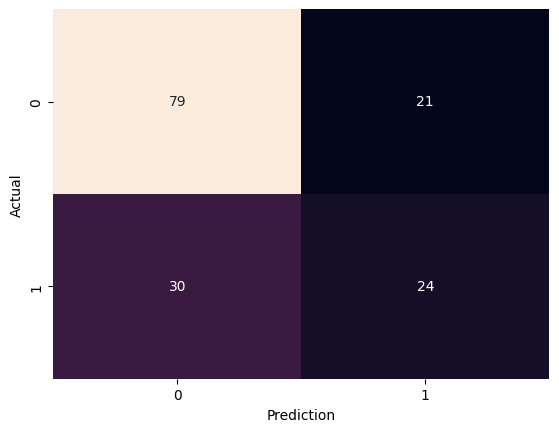

정확도 0.7207792207792207
정밀도 0.6170212765957447
재현율 0.5370370370370371
f1 0.5742574257425742


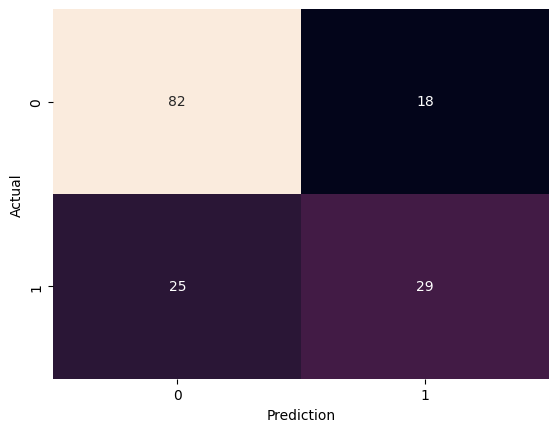

In [70]:
for name,clf in model.items():
  clf.fit(x_train_s,y_train)
  y_pred = clf.predict(x_test_s)
  print_metrics(y_test,y_pred)

정확도 0.6948051948051948
정밀도 0.5777777777777777
재현율 0.48148148148148145
f1 0.5252525252525253


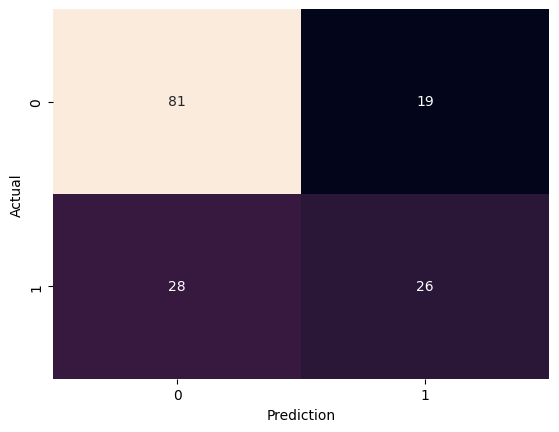

In [75]:
model = LogisticRegression(random_state=SEED)
model.fit(x_train_s,y_train)
y_pred = model.predict(x_test_s)
print_metrics(y_test,y_pred)